In [7]:
# ============================================================
#Import all required libraries
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, string, pickle
from collections import Counter
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import emoji
# If 'internet_words_remover' is not installed, you may need a custom chat‑words mapping
from internet_words_remover import words_remover
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from scipy.sparse import hstack

# Download NLTK resources (if not already done)
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

# Plot settings
sns.set_style('whitegrid')
%matplotlib inline

In [9]:
# Cell 1: Load and combine the TSV files with proper column names
import pandas as pd

# Define column names exactly as requested
col_names = [
    'ID',                    # 1. ID
    'title',                 # 2. title (statement)
    'label',                 # 3. label
]

# Read the files without header and assign the column names
train = pd.read_csv('c19_train.csv', skiprows=1, header=None, names=col_names)
test  = pd.read_csv('c19_test.csv', skiprows=1, header=None, names=col_names)
valid = pd.read_csv('c19_valid.csv',skiprows=1, header=None, names=col_names)

print("Train shape:", train.shape)
print("Test shape :", test.shape)
print("Valid shape:", valid.shape)

# Combine them into one master DataFrame
df_raw = pd.concat([train, test, valid], ignore_index=True)
print("\nCombined shape:", df_raw.shape)
df_raw.head()

Train shape: (6420, 3)
Test shape : (2140, 3)
Valid shape: (2140, 3)

Combined shape: (10700, 3)


,ID,title,label
0,1,The CDC currently reports 99031 deaths. In gen...,real
1,2,States reported 1121 deaths a small rise from ...,real
2,3,Politically Correct Woman (Almost) Uses Pandem...,fake
3,4,#IndiaFightsCorona: We have 1524 #COVID testin...,real
4,5,Populous states can generate large case counts...,real


In [11]:
df_raw.to_csv('Covid19.csv', index=False)

In [13]:
# Check column names and a few rows
print("Columns:", df_raw.columns.tolist())
display(df_raw.head(2))

# Look at unique labels
print("\nOriginal labels and counts:")
print(df_raw['label'].value_counts())

Columns: ['ID', 'title', 'label']


,ID,title,label
0,1,The CDC currently reports 99031 deaths. In gen...,real
1,2,States reported 1121 deaths a small rise from ...,real



Original labels and counts:
label
real    5600
fake    5100
Name: count, dtype: int64


In [15]:
# Define mapping for binary classes (fake=1, real=0)
def map_label(x):
    if x == 'fake':
        return 1
    elif x == 'real':
        return 0
    else:
        return None   # discard unknown

df_raw['label_binary'] = df_raw['label'].apply(map_label)

# Drop rows with unknown labels (if any)
df_raw = df_raw.dropna(subset=['label_binary']).copy()
df_raw['label'] = df_raw['label_binary'].astype(int)
df_raw.drop(columns=['label_binary'], inplace=True)

print("After mapping:")
print(df_raw['label'].value_counts())

After mapping:
label
0    5600
1    5100
Name: count, dtype: int64


In [17]:
# Cell 4: Quick look at the data after label mapping
# We'll work directly with df_raw (already has 'label' as 0/1)
print("Fake news shape:", df_raw[df_raw['label'] == 1].shape)
print("Real news shape:", df_raw[df_raw['label'] == 0].shape)

print("\nFake news columns:", df_raw.columns.tolist())
print("Real news columns:", df_raw.columns.tolist())

# Show a couple of examples
display(df_raw[df_raw['label'] == 1].head(2))
display(df_raw[df_raw['label'] == 0].head(2))

Fake news shape: (5100, 3)
Real news shape: (5600, 3)

Fake news columns: ['ID', 'title', 'label']
Real news columns: ['ID', 'title', 'label']


,ID,title,label
2,3,Politically Correct Woman (Almost) Uses Pandem...,1
7,8,Obama Calls Trump’s Coronavirus Response A Cha...,1


,ID,title,label
0,1,The CDC currently reports 99031 deaths. In gen...,0
1,2,States reported 1121 deaths a small rise from ...,0


In [19]:
# Cell 5: Data types and missing values overview
print("=== df_raw info ===")
df_raw.info()
print("\nMissing values per column:")
print(df_raw.isnull().sum())

=== df_raw info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10700 entries, 0 to 10699
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   ID      10700 non-null  int64 
 1   title   10700 non-null  object
 2   label   10700 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 250.9+ KB

Missing values per column:
ID       0
title    0
label    0
dtype: int64


In [21]:
# Cell 6: Combine, shuffle, and create master DataFrame
df = df_raw.sample(frac=1, random_state=42).reset_index(drop=True)
print("Combined dataset shape:", df.shape)
display(df.head(3))

Combined dataset shape: (10700, 3)


,ID,title,label
0,3705,For our #coronawarriors\n#CoronavirusIndia #In...,1
1,10,Breakdown of testing: 4 air crew 97 hotel &amp...,0
2,305,Indian media outlets claimed that a man in Mad...,1


In [23]:
# Cell 7: Identify main text column (the statement is in 'title')
text_col = 'title'
print("Text column:", text_col)

Text column: title


In [25]:
# Cell 8: Keep only title and label
print("Missing values per column before drop:")
print(df.isnull().sum())

# Drop all columns except title and label
columns_to_keep = ['title', 'label']
df = df[columns_to_keep].copy()
print("\nAfter dropping unnecessary columns:")
print(df.isnull().sum())
df.head()

Missing values per column before drop:
ID       0
title    0
label    0
dtype: int64

After dropping unnecessary columns:
title    0
label    0
dtype: int64


,title,label
0,For our #coronawarriors\n#CoronavirusIndia #In...,1
1,Breakdown of testing: 4 air crew 97 hotel &amp...,0
2,Indian media outlets claimed that a man in Mad...,1
3,Some countries put in place export restriction...,0
4,An additional significant cluster - Matamata -...,0


/var/folders/z3/4jxjt96505s9lmct58gkr4lr0000gn/T/ipykernel_83229/3117622208.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='Set2')


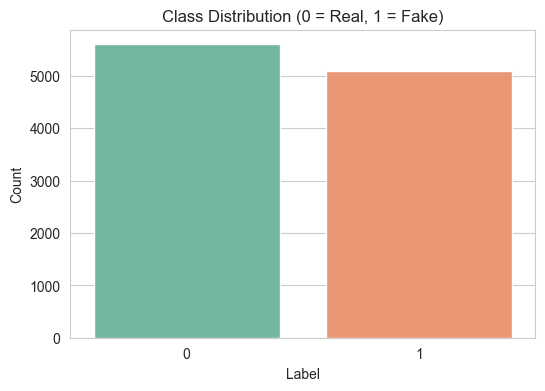

Label counts:
 label
0    5600
1    5100
Name: count, dtype: int64


In [27]:
# Cell 9: Class distribution
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df, palette='Set2')
plt.title('Class Distribution (0 = Real, 1 = Fake)')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()
print("Label counts:\n", df['label'].value_counts())

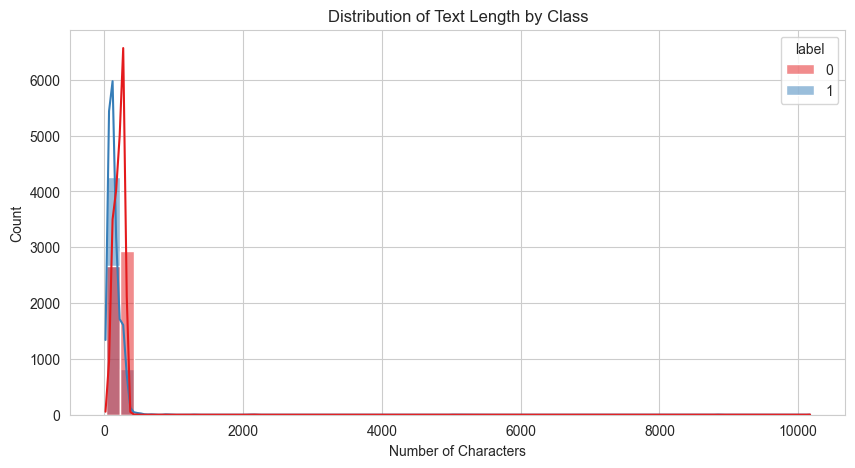

Text length statistics by label:
        count        mean         std   min     25%    50%    75%      max
label                                                                     
0      5600.0  217.124107  150.402974  34.0  155.00  227.0  272.0  10170.0
1      5100.0  143.210588  166.785284  18.0   82.75  118.0  174.0   8846.0


In [29]:
# Cell 10: Text length analysis
df['text_len'] = df[text_col].astype(str).apply(len)

plt.figure(figsize=(10,5))
sns.histplot(data=df, x='text_len', hue='label', bins=50, kde=True, palette='Set1')
plt.title('Distribution of Text Length by Class')
plt.xlabel('Number of Characters')
plt.show()

print("Text length statistics by label:")
print(df.groupby('label')['text_len'].describe())

/var/folders/z3/4jxjt96505s9lmct58gkr4lr0000gn/T/ipykernel_83229/3913268402.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='word_count', data=df, palette='Set3')


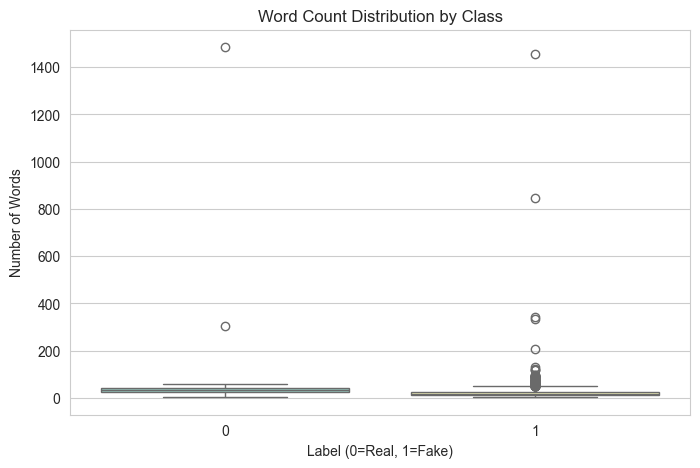

Word count statistics by label:
        count       mean        std  min   25%   50%   75%     max
label                                                             
0      5600.0  31.967500  22.500906  3.0  23.0  32.0  40.0  1484.0
1      5100.0  21.652941  27.335185  3.0  12.0  17.0  27.0  1456.0


In [31]:
# Cell 11: Word count analysis
df['word_count'] = df[text_col].astype(str).apply(lambda x: len(x.split()))

plt.figure(figsize=(8,5))
sns.boxplot(x='label', y='word_count', data=df, palette='Set3')
plt.title('Word Count Distribution by Class')
plt.xlabel('Label (0=Real, 1=Fake)')
plt.ylabel('Number of Words')
plt.show()

print("Word count statistics by label:")
print(df.groupby('label')['word_count'].describe())

/var/folders/z3/4jxjt96505s9lmct58gkr4lr0000gn/T/ipykernel_83229/1984756284.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='unique_words', data=df, palette='pastel')


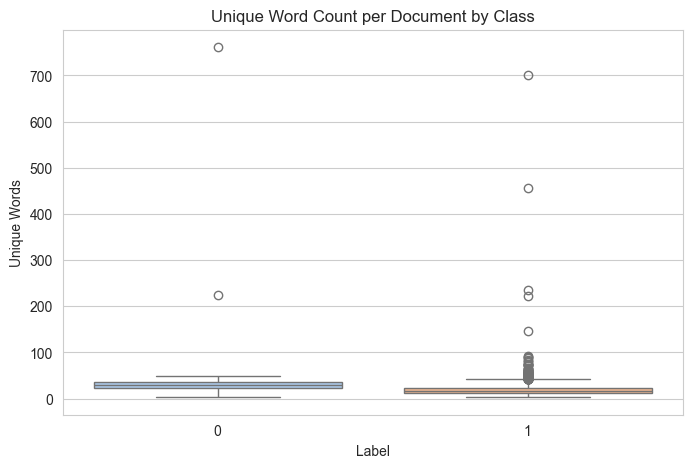

Unique word count statistics by label:
        count       mean        std  min   25%   50%   75%    max
label                                                            
0      5600.0  28.290893  13.303827  3.0  22.0  29.0  35.0  761.0
1      5100.0  19.706078  16.135910  3.0  12.0  16.0  24.0  701.0


In [33]:
# Cell 12: Unique word count per document
df['unique_words'] = df[text_col].astype(str).apply(lambda x: len(set(x.lower().split())))

plt.figure(figsize=(8,5))
sns.boxplot(x='label', y='unique_words', data=df, palette='pastel')
plt.title('Unique Word Count per Document by Class')
plt.xlabel('Label')
plt.ylabel('Unique Words')
plt.show()

print("Unique word count statistics by label:")
print(df.groupby('label')['unique_words'].describe())

In [35]:
# Cell 13: Most frequent words after removing stopwords
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from collections import Counter

nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)

stop_words = set(stopwords.words('english'))

def get_top_words(text_series, n_top=20):
    all_text = ' '.join(text_series.astype(str))
    words = all_text.lower().split()
    # Keep only alphabetic tokens and remove stopwords
    words = [w for w in words if w.isalpha() and w not in stop_words]
    return Counter(words).most_common(n_top)

print("Top 20 words in FAKE news:")
print(get_top_words(df[df['label'] == 1][text_col]))

print("\nTop 20 words in REAL news:")
print(get_top_words(df[df['label'] == 0][text_col]))

Top 20 words in FAKE news:
[('coronavirus', 1275), ('people', 455), ('new', 343), ('trump', 332), ('says', 320), ('video', 307), ('vaccine', 282), ('virus', 257), ('president', 243), ('covid', 221), ('shows', 219), ('hospital', 217), ('cases', 215), ('india', 205), ('claims', 197), ('said', 189), ('pandemic', 182), ('corona', 177), ('claim', 177), ('government', 170)]

Top 20 words in REAL news:
[('cases', 2252), ('new', 1442), ('tests', 939), ('number', 789), ('total', 775), ('people', 727), ('confirmed', 712), ('reported', 704), ('deaths', 668), ('states', 659), ('testing', 609), ('health', 447), ('rt', 437), ('report', 415), ('state', 392), ('one', 375), ('daily', 369), ('update', 363), ('today', 359), ('data', 341)]


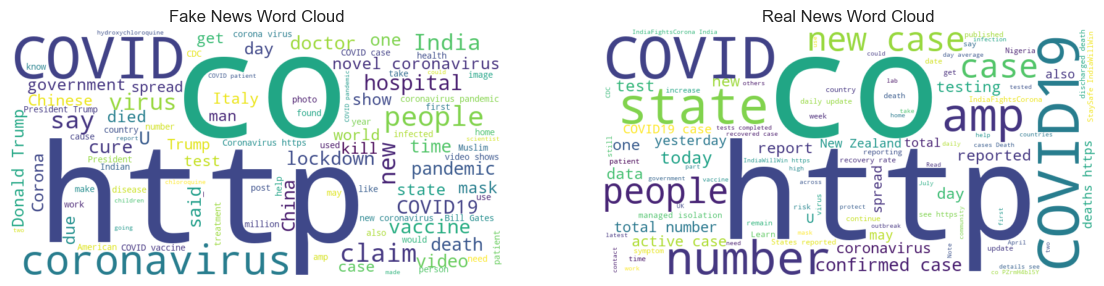

In [37]:
# Cell 14: Word clouds
from wordcloud import WordCloud

fake_text = ' '.join(df[df['label'] == 1][text_col].astype(str))
real_text = ' '.join(df[df['label'] == 0][text_col].astype(str))

wc_fake = WordCloud(stopwords=stop_words, max_words=100, background_color='white',
                    width=800, height=400, random_state=42).generate(fake_text)
wc_real = WordCloud(stopwords=stop_words, max_words=100, background_color='white',
                    width=800, height=400, random_state=42).generate(real_text)

plt.figure(figsize=(14,7))
plt.subplot(1,2,1)
plt.imshow(wc_fake, interpolation='bilinear')
plt.title('Fake News Word Cloud')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(wc_real, interpolation='bilinear')
plt.title('Real News Word Cloud')
plt.axis('off')
plt.show()

In [39]:
# Cell 15: Top bigrams for each class
from sklearn.feature_extraction.text import CountVectorizer

def get_top_ngrams(corpus, ngram_range=(2,2), top_n=20):
    vec = CountVectorizer(ngram_range=ngram_range, stop_words='english')
    bow = vec.fit_transform(corpus.astype(str))
    freq = bow.sum(axis=0).A1
    ngrams = {idx: word for word, idx in vec.vocabulary_.items()}
    sorted_ngrams = sorted(zip(ngrams.values(), freq), key=lambda x: x[1], reverse=True)
    return sorted_ngrams[:top_n]

print("Top 20 bigrams in FAKE news:")
for bg, count in get_top_ngrams(df[df['label'] == 1][text_col], (2,2)):
    print(f"{bg}: {count}")

print("\nTop 20 bigrams in REAL news:")
for bg, count in get_top_ngrams(df[df['label'] == 0][text_col], (2,2)):
    print(f"{bg}: {count}")

Top 20 bigrams in FAKE news:
vaccine compulsory: 1658
aids condition: 153
raising long: 137
venice canals: 111
trump announce: 104
studies small: 96
episode mrs: 77
provide temporary: 76
claim ignores: 74
burundi died: 65
does countries: 63
obesity does: 63
contaminated covid: 63
post shared: 60
indian parliament: 59
cured bowl: 58
fencing tokyo2020: 57
end start: 57
wants digital: 53
jjtm0xuuvq https: 53

Top 20 bigrams in REAL news:
order online: 1156
yxprulkckq https: 508
feeling government: 481
team grueling: 320
week reporting: 320
people urged: 218
thermometers blood: 202
11 borno: 201
scale state: 198
technique wa: 192
sunday people: 184
https bmuvceemip: 179
covid recoveries: 178
follow accounts: 175
finds https: 162
food security: 155
confirmed 42439: 145
results 1300: 136
increasing 8th: 131
reach new: 131


Title Length Statistics:
count    10700.000000
mean       181.894299
std        162.660269
min         18.000000
25%        110.000000
50%        169.000000
75%        255.000000
max      10170.000000
Name: title_len, dtype: float64


METHOD 1: IQR Method
Q1: 110.00
Q3: 255.00
IQR: 145.00
Lower bound: -107.50
Upper bound: 472.50
Number of outliers: 24 (0.22%)
Outlier range: < -108 or > 472 characters

METHOD 2: Z-Score Method
Z-score threshold: 3
Number of outliers: 13 (0.12%)

METHOD 3: Percentile Method
Lower 1th percentile: 43.00
Upper 99th percentile: 317.00
Number of outliers: 208 (1.94%)

METHOD 4: Modified Z-Score (MAD)
Median: 169.00
MAD: 70.00
Threshold: 3.5
Number of outliers: 17 (0.16%)


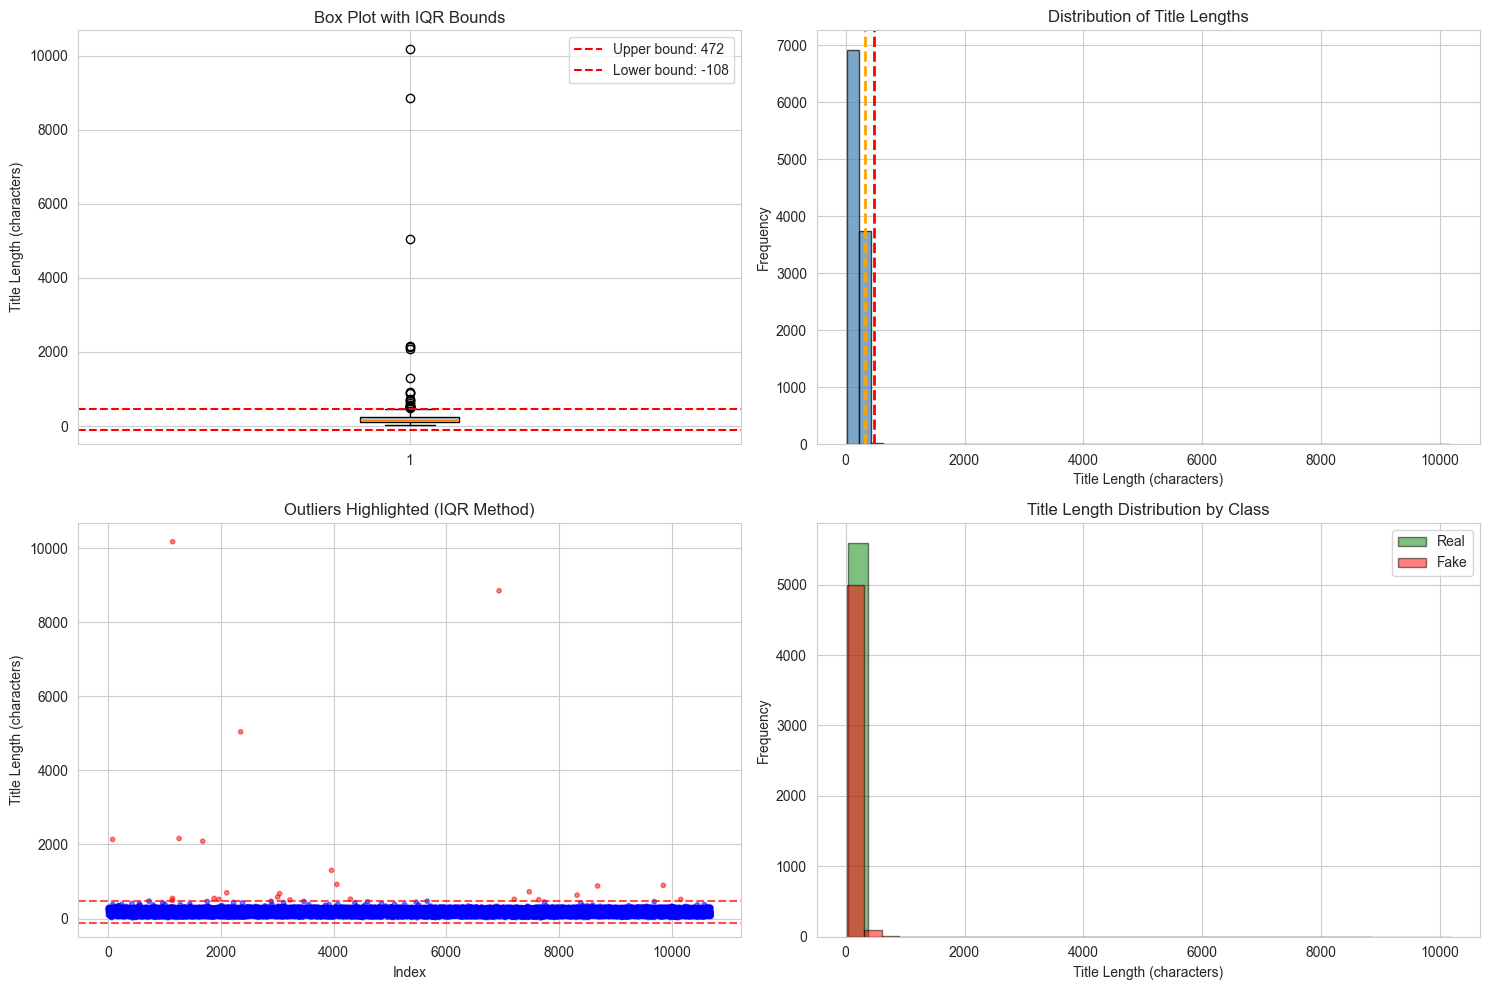


SAMPLE OF OUTLIERS (IQR Method)


,Title,Length,Label
79,I'm so happy that we’re able to do something v...,2135,0
1139,@LBGoodnessGrows @JamesDSteinberg @RapidTests ...,486,1
1141,Mask wearers beware. A caller to a radio talk ...,545,1
1143,I’ve never had a chance to work on something t...,10170,0
1258,NYC man drops dead in middle of street — suspe...,2160,1
1678,Man visited Albany N.Y. days before dying from...,2086,1
1881,Mask wearers beware. A caller to a radio talk ...,545,1
1964,A Good News* Finally an INDIAN student from PO...,520,1
2103,"COVID-19, Take one minute and read. Be underst...",695,1
2350,"Actors"" applauded Macron when he visited the s...",5040,1



OUTLIER DETECTION SUMMARY


,Method,Total Outliers,Percentage
0,IQR,24,0.22%
1,Z-Score,13,0.12%
2,Percentile (1-99),208,1.94%
3,Modified Z-Score (MAD),17,0.16%


In [41]:
# Cell: Outlier Detection for Text Length in Title Column
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check if title column exists
if 'title' in df.columns:
    # Calculate title length
    df['title_len'] = df['title'].astype(str).apply(len)
    
    print("Title Length Statistics:")
    print(df['title_len'].describe())
    print("\n")
    
    # ============================================
    # METHOD 1: IQR (Interquartile Range) Method
    # ============================================
    Q1 = df['title_len'].quantile(0.25)
    Q3 = df['title_len'].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound_iqr = Q1 - 1.5 * IQR
    upper_bound_iqr = Q3 + 1.5 * IQR
    
    outliers_iqr = df[(df['title_len'] < lower_bound_iqr) | (df['title_len'] > upper_bound_iqr)]
    
    print("="*50)
    print("METHOD 1: IQR Method")
    print("="*50)
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower bound: {lower_bound_iqr:.2f}")
    print(f"Upper bound: {upper_bound_iqr:.2f}")
    print(f"Number of outliers: {len(outliers_iqr)} ({len(outliers_iqr)/len(df)*100:.2f}%)")
    print(f"Outlier range: < {lower_bound_iqr:.0f} or > {upper_bound_iqr:.0f} characters")
    
    # ============================================
    # METHOD 2: Z-Score Method
    # ============================================
    from scipy import stats
    
    z_scores = np.abs(stats.zscore(df['title_len'].dropna()))
    threshold_z = 3
    outliers_zscore = df.iloc[df['title_len'].dropna().index][z_scores > threshold_z]
    
    print("\n" + "="*50)
    print("METHOD 2: Z-Score Method")
    print("="*50)
    print(f"Z-score threshold: {threshold_z}")
    print(f"Number of outliers: {len(outliers_zscore)} ({len(outliers_zscore)/len(df)*100:.2f}%)")
    
    # ============================================
    # METHOD 3: Percentile Method
    # ============================================
    lower_percentile = 1
    upper_percentile = 99
    
    lower_bound_pct = df['title_len'].quantile(lower_percentile/100)
    upper_bound_pct = df['title_len'].quantile(upper_percentile/100)
    
    outliers_percentile = df[(df['title_len'] < lower_bound_pct) | (df['title_len'] > upper_bound_pct)]
    
    print("\n" + "="*50)
    print("METHOD 3: Percentile Method")
    print("="*50)
    print(f"Lower {lower_percentile}th percentile: {lower_bound_pct:.2f}")
    print(f"Upper {upper_percentile}th percentile: {upper_bound_pct:.2f}")
    print(f"Number of outliers: {len(outliers_percentile)} ({len(outliers_percentile)/len(df)*100:.2f}%)")
    
    # ============================================
    # METHOD 4: Modified Z-Score (MAD) - Robust to outliers
    # ============================================
    median = df['title_len'].median()
    mad = np.median(np.abs(df['title_len'] - median))
    modified_z_scores = 0.6745 * (df['title_len'] - median) / mad
    threshold_mad = 3.5
    outliers_mad = df[np.abs(modified_z_scores) > threshold_mad]
    
    print("\n" + "="*50)
    print("METHOD 4: Modified Z-Score (MAD)")
    print("="*50)
    print(f"Median: {median:.2f}")
    print(f"MAD: {mad:.2f}")
    print(f"Threshold: {threshold_mad}")
    print(f"Number of outliers: {len(outliers_mad)} ({len(outliers_mad)/len(df)*100:.2f}%)")
    
    # ============================================
    # VISUALIZATION
    # ============================================
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # Box plot with IQR outliers highlighted
    ax1 = axes[0, 0]
    bp = ax1.boxplot(df['title_len'].dropna(), vert=True, patch_artist=True)
    bp['boxes'][0].set_facecolor('lightblue')
    ax1.axhline(y=upper_bound_iqr, color='red', linestyle='--', label=f'Upper bound: {upper_bound_iqr:.0f}')
    ax1.axhline(y=lower_bound_iqr, color='red', linestyle='--', label=f'Lower bound: {lower_bound_iqr:.0f}')
    ax1.set_title('Box Plot with IQR Bounds')
    ax1.set_ylabel('Title Length (characters)')
    ax1.legend()
    
    # Histogram with KDE
    ax2 = axes[0, 1]
    ax2.hist(df['title_len'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    ax2.axvline(x=upper_bound_iqr, color='red', linestyle='--', linewidth=2)
    ax2.axvline(x=upper_bound_pct, color='orange', linestyle='--', linewidth=2)
    ax2.set_title('Distribution of Title Lengths')
    ax2.set_xlabel('Title Length (characters)')
    ax2.set_ylabel('Frequency')
    
    # Scatter plot (index vs length) with outliers highlighted
    ax3 = axes[1, 0]
    colors = np.where((df['title_len'] >= lower_bound_iqr) & (df['title_len'] <= upper_bound_iqr), 'blue', 'red')
    ax3.scatter(range(len(df)), df['title_len'], c=colors, alpha=0.5, s=10)
    ax3.axhline(y=upper_bound_iqr, color='red', linestyle='--', alpha=0.7)
    ax3.axhline(y=lower_bound_iqr, color='red', linestyle='--', alpha=0.7)
    ax3.set_title('Outliers Highlighted (IQR Method)')
    ax3.set_xlabel('Index')
    ax3.set_ylabel('Title Length (characters)')
    
    # Distribution by label
    ax4 = axes[1, 1]
    for label_val, color, name in [(0, 'green', 'Real'), (1, 'red', 'Fake')]:
        subset = df[df['label'] == label_val]
        ax4.hist(subset['title_len'], bins=30, alpha=0.5, color=color, label=name, edgecolor='black')
    ax4.set_title('Title Length Distribution by Class')
    ax4.set_xlabel('Title Length (characters)')
    ax4.set_ylabel('Frequency')
    ax4.legend()
    
    plt.tight_layout()
    plt.show()
    
    # ============================================
    # SHOW SAMPLE OUTLIERS
    # ============================================
    print("\n" + "="*50)
    print("SAMPLE OF OUTLIERS (IQR Method)")
    print("="*50)
    if len(outliers_iqr) > 0:
        display(outliers_iqr[['title', 'title_len', 'label']].head(10)
               .rename(columns={'title': 'Title', 'title_len': 'Length', 'label': 'Label'}))
    else:
        print("No outliers found with IQR method.")
    
    # ============================================
    # SUMMARY TABLE
    # ============================================
    print("\n" + "="*50)
    print("OUTLIER DETECTION SUMMARY")
    print("="*50)
    summary_data = {
        'Method': ['IQR', 'Z-Score', 'Percentile (1-99)', 'Modified Z-Score (MAD)'],
        'Total Outliers': [
            len(outliers_iqr),
            len(outliers_zscore),
            len(outliers_percentile),
            len(outliers_mad)
        ],
        'Percentage': [
            f"{len(outliers_iqr)/len(df)*100:.2f}%",
            f"{len(outliers_zscore)/len(df)*100:.2f}%",
            f"{len(outliers_percentile)/len(df)*100:.2f}%",
            f"{len(outliers_mad)/len(df)*100:.2f}%"
        ]
    }
    summary_df = pd.DataFrame(summary_data)
    display(summary_df)
    
else:
    print("Error: 'title' column not found in the dataset.")
    print("Available columns:", df.columns.tolist())

In [43]:
# Optional Cell: Create outlier flag and filter dataset
# Add outlier flags to the dataset
df['is_outlier_title_len_iqr'] = (df['title_len'] < lower_bound_iqr) | (df['title_len'] > upper_bound_iqr)
df['is_outlier_title_len_zscore'] = z_scores > threshold_z

print("Sample data with outlier flags:")
display(df[['title', 'title_len', 'is_outlier_title_len_iqr', 'label']].sample(50))

# Optional: Filter out outliers
df_no_outliers = df[~df['is_outlier_title_len_iqr']]
print(f"\nOriginal dataset shape: {df.shape}")
print(f"Dataset without title length outliers: {df_no_outliers.shape}")

Sample data with outlier flags:


,title,title_len,is_outlier_title_len_iqr,label
8683,@Narvuntien @jimdtweet @MedBennett @TheDisproo...,880,True,1
697,"Sector 5, Harola, Noida who came in contact wi...",94,False,1
1356,Multiple Facebook posts shared thousands of ti...,285,False,1
4720,UPDATE: #COVID19 ➡Emergency healthcare seeking...,272,False,0
8230,Says Daniel Radcliffe has the coronavirus.,42,False,1
1655,Updated on April 22: 50 U.S. states D.C. &amp;...,274,False,0
3014,Senegalese people flying back from Italy were ...,88,False,1
10637,RT @PolitiFactWisc: Wisconsin is trending poor...,111,False,1
8042,“At the onset of #COVID19Nigeria cases with tr...,303,False,0
5871,Katy Perry Secretly Relieved Her Wedding To Or...,118,False,1



Original dataset shape: (10700, 8)
Dataset without title length outliers: (10676, 8)


In [45]:
# Optional Cell: Analyze outlier characteristics
print("Outlier analysis by class:")
print("="*50)
for label_val, label_name in [(0, 'Real'), (1, 'Fake')]:
    total_in_class = len(df[df['label'] == label_val])
    outliers_in_class = len(outliers_iqr[outliers_iqr['label'] == label_val])
    print(f"{label_name} news:")
    print(f"  Total articles: {total_in_class}")
    print(f"  Outliers: {outliers_in_class} ({outliers_in_class/total_in_class*100:.2f}%)")
    print(f"  Mean title length: {df[df['label']==label_val]['title_len'].mean():.2f}")
    print(f"  Outlier mean title length: {outliers_iqr[outliers_iqr['label']==label_val]['title_len'].mean() if outliers_in_class > 0 else 'N/A'}")

Outlier analysis by class:
Real news:
  Total articles: 5600
  Outliers: 2 (0.04%)
  Mean title length: 217.12
  Outlier mean title length: 6152.5
Fake news:
  Total articles: 5100
  Outliers: 22 (0.43%)
  Mean title length: 143.21
  Outlier mean title length: 1368.5454545454545


REMOVING OUTLIERS: PERCENTILE METHOD (1-99)
Lower bound (1st percentile): 43.00 characters
Upper bound (99th percentile): 317.00 characters
Acceptable range: 43.00 - 317.00 characters

Total outliers detected: 208 (1.94%)
  - Fake news outliers: 196
  - Real news outliers: 12

SAMPLE OF ROWS TO BE REMOVED


,Title,Length,Label
66,WHO changed its directives,26,1
79,I'm so happy that we’re able to do something v...,2135,0
81,_A video has been viewed millions of times in ...,377,1
104,Lock down exit will bump up CORONA Cases to 40...,320,1
180,Chinese are not taking any medicine or any vac...,349,1
190,This is not normally what I'll share on my pag...,347,1
241,@Robbiedocs @BrigCM123 @steven_reaney @colstee...,381,1
273,Mustard oil can kill coronavirus.,33,1
318,When you listen / share d thoughts of Migrants...,326,1
421,Another Doctor lost due to COVID-19 ?\n*******...,402,1



DATASET AFTER REMOVING OUTLIERS
Original shape: (10700, 8)
New shape: (10492, 8)
Rows removed: 208 (1.94%)

Class distribution after removal:
Real news (0): 5588 (53.26%)
Fake news (1): 4904 (46.74%)

Title length statistics after removal:
count    10492.000000
mean       178.320244
std         77.555997
min         43.000000
25%        111.000000
50%        169.000000
75%        254.000000
max        317.000000
Name: title_len, dtype: float64


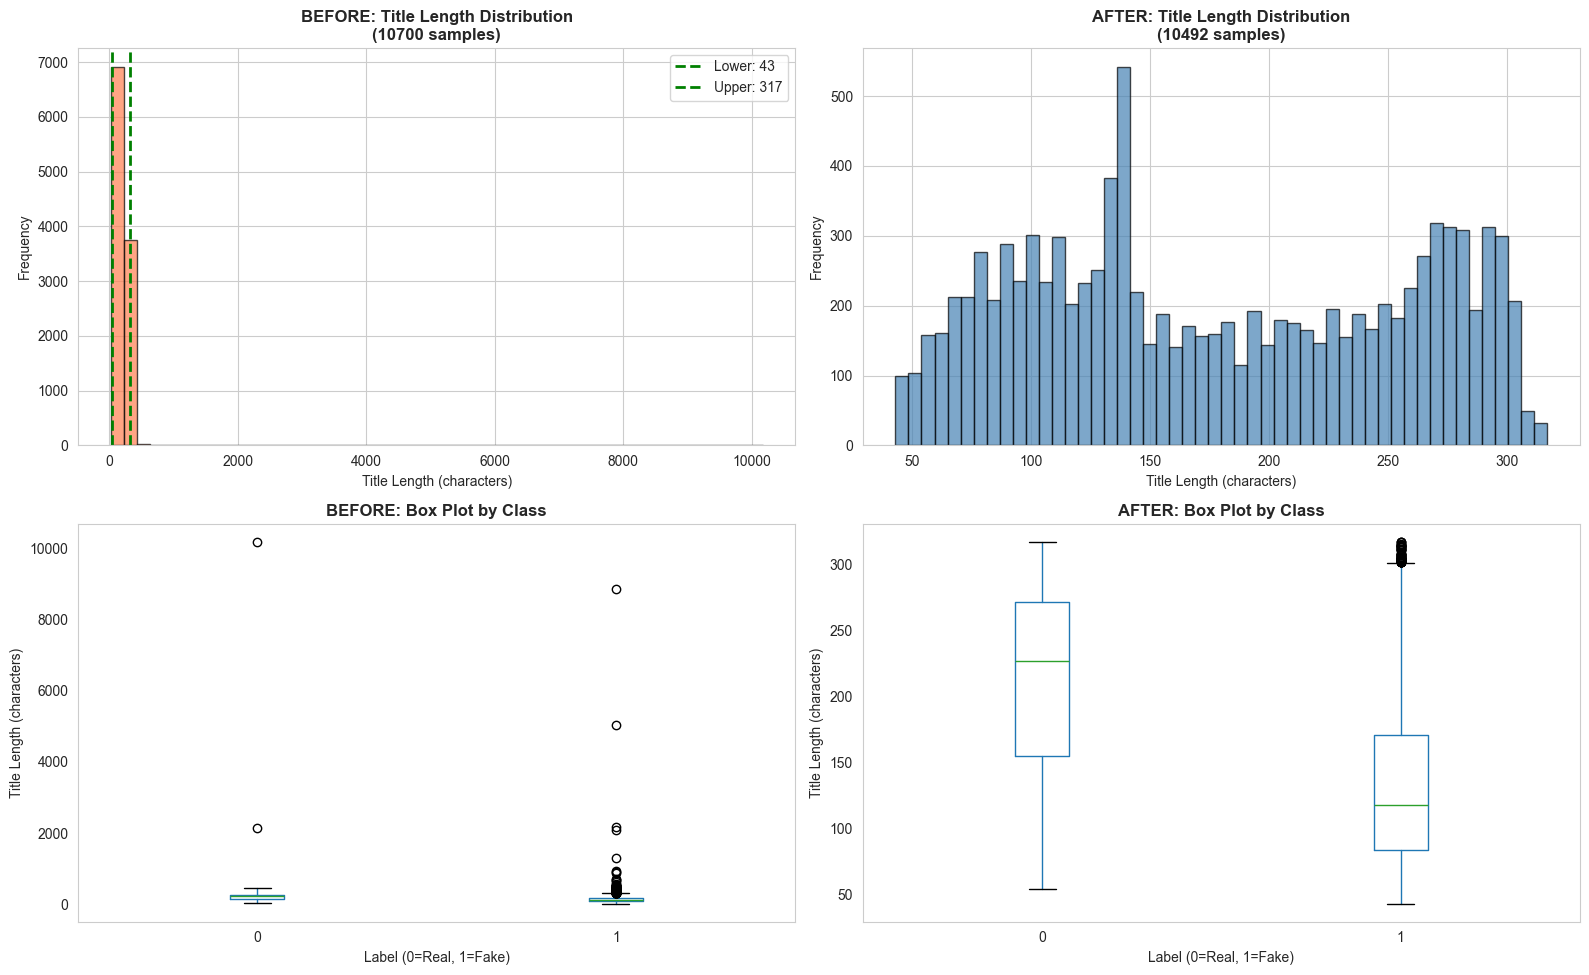


VERIFICATION
✓ SUCCESS: No outliers remaining in the cleaned dataset.

Cleaned dataset ready for use!
Variable 'df_clean' now contains the dataset without title length outliers.


In [47]:
# Cell: Remove Outliers Using Percentile (1-99) Method
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Check if title column exists and title_len has been calculated
if 'title' in df.columns and 'title_len' in df.columns:
    
    # Calculate percentile bounds
    lower_percentile = 1
    upper_percentile = 99
    
    lower_bound = df['title_len'].quantile(lower_percentile/100)
    upper_bound = df['title_len'].quantile(upper_percentile/100)
    
    print("="*60)
    print("REMOVING OUTLIERS: PERCENTILE METHOD (1-99)")
    print("="*60)
    print(f"Lower bound (1st percentile): {lower_bound:.2f} characters")
    print(f"Upper bound (99th percentile): {upper_bound:.2f} characters")
    print(f"Acceptable range: {lower_bound:.2f} - {upper_bound:.2f} characters")
    
    # Identify outliers
    outlier_mask = (df['title_len'] < lower_bound) | (df['title_len'] > upper_bound)
    num_outliers = outlier_mask.sum()
    num_removed_fake = outlier_mask[df['label'] == 1].sum()
    num_removed_real = outlier_mask[df['label'] == 0].sum()
    
    print(f"\nTotal outliers detected: {num_outliers} ({num_outliers/len(df)*100:.2f}%)")
    print(f"  - Fake news outliers: {num_removed_fake}")
    print(f"  - Real news outliers: {num_removed_real}")
    
    # Show sample of rows being removed
    print("\n" + "="*60)
    print("SAMPLE OF ROWS TO BE REMOVED")
    print("="*60)
    outliers_df = df[outlier_mask]
    if len(outliers_df) > 0:
        display(outliers_df[['title', 'title_len', 'label']].head(10)
               .rename(columns={'title': 'Title', 'title_len': 'Length', 'label': 'Label'}))
    else:
        print("No outliers to remove!")
    
    # Save original shape for comparison
    original_shape = df.shape
    
    # Remove outliers
    df_clean = df[~outlier_mask].copy()
    
    # Reset index after removal
    df_clean = df_clean.reset_index(drop=True)
    
    print("\n" + "="*60)
    print("DATASET AFTER REMOVING OUTLIERS")
    print("="*60)
    print(f"Original shape: {original_shape}")
    print(f"New shape: {df_clean.shape}")
    print(f"Rows removed: {original_shape[0] - df_clean.shape[0]} ({(original_shape[0] - df_clean.shape[0])/original_shape[0]*100:.2f}%)")
    
    # Check class distribution after removal
    print("\nClass distribution after removal:")
    print(f"Real news (0): {df_clean[df_clean['label']==0].shape[0]} ({df_clean[df_clean['label']==0].shape[0]/df_clean.shape[0]*100:.2f}%)")
    print(f"Fake news (1): {df_clean[df_clean['label']==1].shape[0]} ({df_clean[df_clean['label']==1].shape[0]/df_clean.shape[0]*100:.2f}%)")
    
    # Title length statistics after removal
    print("\nTitle length statistics after removal:")
    print(df_clean['title_len'].describe())
    
    # ============================================
    # VISUALIZATION: Before vs After
    # ============================================
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    
    # Before - Distribution
    ax1 = axes[0, 0]
    ax1.hist(df['title_len'], bins=50, edgecolor='black', alpha=0.7, color='coral')
    ax1.axvline(x=lower_bound, color='green', linestyle='--', linewidth=2, label=f'Lower: {lower_bound:.0f}')
    ax1.axvline(x=upper_bound, color='green', linestyle='--', linewidth=2, label=f'Upper: {upper_bound:.0f}')
    ax1.set_title(f'BEFORE: Title Length Distribution\n({original_shape[0]} samples)', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Title Length (characters)')
    ax1.set_ylabel('Frequency')
    ax1.legend()
    
    # After - Distribution
    ax2 = axes[0, 1]
    ax2.hist(df_clean['title_len'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    ax2.set_title(f'AFTER: Title Length Distribution\n({df_clean.shape[0]} samples)', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Title Length (characters)')
    ax2.set_ylabel('Frequency')
    
    # Before - Box plot by class
    ax3 = axes[1, 0]
    df.boxplot(column='title_len', by='label', ax=ax3, grid=False)
    ax3.set_title('BEFORE: Box Plot by Class', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Label (0=Real, 1=Fake)')
    ax3.set_ylabel('Title Length (characters)')
    ax3.get_figure().suptitle('')  # Remove pandas default title
    
    # After - Box plot by class
    ax4 = axes[1, 1]
    df_clean.boxplot(column='title_len', by='label', ax=ax4, grid=False)
    ax4.set_title('AFTER: Box Plot by Class', fontsize=12, fontweight='bold')
    ax4.set_xlabel('Label (0=Real, 1=Fake)')
    ax4.set_ylabel('Title Length (characters)')
    ax4.get_figure().suptitle('')  # Remove pandas default title
    
    plt.tight_layout()
    plt.show()
    
    # ============================================
    # VERIFICATION: Check no outliers remain
    # ============================================
    remaining_outliers = df_clean[(df_clean['title_len'] < lower_bound) | (df_clean['title_len'] > upper_bound)]
    
    print("\n" + "="*60)
    print("VERIFICATION")
    print("="*60)
    if len(remaining_outliers) == 0:
        print("✓ SUCCESS: No outliers remaining in the cleaned dataset.")
    else:
        print(f"⚠ WARNING: {len(remaining_outliers)} outliers still present.")
    
    print(f"\nCleaned dataset ready for use!")
    print(f"Variable 'df_clean' now contains the dataset without title length outliers.")
    
    # Optional: Overwrite original df
    # Uncomment the next line to replace df with the cleaned version
    # df = df_clean
    
else:
    print("Error: 'title' column not found or 'title_len' not calculated.")
    print("Please run the title length calculation first:")
    print("  df['title_len'] = df['title'].astype(str).apply(len)")
    if 'title' not in df.columns:
        print("Available columns:", df.columns.tolist())

In [49]:
df_clean.head()

,title,label,text_len,word_count,unique_words,title_len,is_outlier_title_len_iqr,is_outlier_title_len_zscore
0,For our #coronawarriors\n#CoronavirusIndia #In...,1,241,25,23,241,False,False
1,Breakdown of testing: 4 air crew 97 hotel &amp...,0,285,47,39,285,False,False
2,Indian media outlets claimed that a man in Mad...,1,95,15,15,95,False,False
3,Some countries put in place export restriction...,0,181,22,22,181,False,False
4,An additional significant cluster - Matamata -...,0,279,47,41,279,False,False


In [51]:
#drop all columns except title and label
df_clean.drop(columns=['text_len', 'word_count', 'unique_words', 'title_len','is_outlier_title_len_iqr','is_outlier_title_len_zscore'], inplace=True)

In [58]:
df_clean.head()

,title,label
0,For our #coronawarriors\n#CoronavirusIndia #In...,1
1,Breakdown of testing: 4 air crew 97 hotel &amp...,0
2,Indian media outlets claimed that a man in Mad...,1
3,Some countries put in place export restriction...,0
4,An additional significant cluster - Matamata -...,0


In [60]:
# Cell: Preprocessing Function
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import emoji
from internet_words_remover import words_remover

# Download required NLTK data (run once)
import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# Initialize NLP tools
stop_words = set(stopwords.words('english'))
wn_lem = WordNetLemmatizer()
punc = str.maketrans('', '', string.punctuation)

def preprocessing(text):
    # 1. Convert to lowercase and strip whitespace
    text = text.lower()
    text = text.strip()
    
    # 2. Remove HTML tags
    text = re.sub(pattern='<.*?>', repl='', string=text)
    
    # 3. Remove URLs
    text = re.sub(pattern=r'https?://\S+|www\.\S+', repl='', string=text)
    
    # 4. Remove punctuation
    text = text.translate(punc)
    
    # 5. Replace chat words
    text = words_remover(text)
    
    # 6. Remove stopwords
    new_text1 = []
    for word in text.split():
        if word not in stop_words:
            new_text1.append(word)
    text = ' '.join(new_text1)
    
    # 7. Convert emojis to text
    text = emoji.demojize(text)
    
    # 8. Lemmatization
    new_text2 = []
    for word in text.split():
        lemmatized_word = wn_lem.lemmatize(word, pos='v')
        new_text2.append(lemmatized_word)
    text = ' '.join(new_text2)
    
    return text

In [62]:
# Apply preprocessing
df_clean['transformed_text'] = df_clean['title'].apply(preprocessing)

print("Preprocessing completed")
print(df_clean.head())

Preprocessing completed
                                               title  label  \
0  For our #coronawarriors\n#CoronavirusIndia #In...      1   
1  Breakdown of testing: 4 air crew 97 hotel &amp...      0   
2  Indian media outlets claimed that a man in Mad...      1   
3  Some countries put in place export restriction...      0   
4  An additional significant cluster - Matamata -...      0   

                                    transformed_text  
0  coronawarriors coronavirusindia indiafightscor...  
1  breakdown test 4 air crew 97 hotel amp health ...  
2  indian media outlets claim man madhya pradeshs...  
3  countries put place export restrictions amp se...  
4  additional significant cluster matamata close ...  


In [64]:
df_clean.to_csv('Covid19_clean.csv', index=False)

### This code for balanced (undersampled)

In [67]:
# Cell: Undersample majority class to balance dataset
import pandas as pd

# Assume df_clean is your current DataFrame with 'label' column (0=Real, 1=Fake)
print("Original class distribution:")
print(df_clean['label'].value_counts())

# Separate classes
df_class_0 = df_clean[df_clean['label'] == 0]   # majority class (adjust if Fake is majority)
df_class_1 = df_clean[df_clean['label'] == 1]

# Find minority count
minority_count = min(len(df_class_0), len(df_class_1))
print(f"\nMinority class count: {minority_count}")

# Undersample the majority class
if len(df_class_0) > minority_count:
    df_class_0_under = df_class_0.sample(n=minority_count, random_state=42)
else:
    df_class_0_under = df_class_0

if len(df_class_1) > minority_count:
    df_class_1_under = df_class_1.sample(n=minority_count, random_state=42)
else:
    df_class_1_under = df_class_1

# Combine back
df_balanced = pd.concat([df_class_0_under, df_class_1_under], ignore_index=True)
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle

print("\nBalanced class distribution:")
print(df_balanced['label'].value_counts())
print(f"New dataset shape: {df_balanced.shape}")

# Optional: overwrite df_clean for subsequent steps
# df_clean = df_balanced

Original class distribution:
label
0    5588
1    4904
Name: count, dtype: int64

Minority class count: 4904

Balanced class distribution:
label
0    4904
1    4904
Name: count, dtype: int64
New dataset shape: (9808, 3)


In [75]:
df_balanced.head(10)

,title,label,transformed_text
0,ICMR COVID-19 testing crossed 3 Lakh. For more...,0,icmr covid19 test cross 3 lakh detail visit ic...
1,The number of people who have tested positive ...,0,number people test positive coronavirus uk jum...
2,Mondays numbers normally show some weekend lag...,0,mondays number normally show weekend lag today...
3,Across five states this week we commenced the ...,0,across five state week commence assessment pub...
4,Our total number of confirmed cases is now 115...,0,total number confirm case 1156 number report w...
5,Deficient in Vitamin D. Myself included as a d...,1,"deficient vitamin include sh*t (e.g., new epis..."
6,There are dozens of posts on Facebook and Twit...,1,dozens post facebook twitter list number plant...
7,Coronavirus: Medical and science experts outli...,0,coronavirus medical science experts outline fo...
8,"Donald Trump has claimed he ""up-played"" the se...",0,donald trump claim upplayed seriousness corona...
9,I heard such type of news many times.. Turkey ...,1,hear type news many time turkey months ago cla...


In [77]:
df_balanced.shape

(9808, 3)

In [79]:
df_balanced.to_csv('Covid19_bal.csv', index=False)

In [81]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_balanced['transformed_text'], 
    df_balanced['label'],            
    test_size=0.2,               
    random_state=42,               
)

In [83]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()
X_train_bow = cv.fit_transform(X_train)
X_test_bow = cv.transform(X_test)

print("BoW feature extraction completed")
print("X_train shape:", X_train_bow.shape)
print("X_test shape:", X_test_bow.shape)

BoW feature extraction completed
X_train shape: (7846, 15515)
X_test shape: (1962, 15515)


In [85]:
import pickle

# Save train vectors
with open("X_train_bow.pkl", "wb") as f:
    pickle.dump(X_train_bow, f)

# Save test vectors
with open("X_test_bow.pkl", "wb") as f:
    pickle.dump(X_test_bow, f)

with open("y_train_bow.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_bow.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("count_vectorizer.pkl", "wb") as f:
    pickle.dump(cv, f)

### till above

In [88]:
df.head()

,title,label,text_len,word_count,unique_words,title_len,is_outlier_title_len_iqr,is_outlier_title_len_zscore
0,For our #coronawarriors\n#CoronavirusIndia #In...,1,241,25,23,241,False,False
1,Breakdown of testing: 4 air crew 97 hotel &amp...,0,285,47,39,285,False,False
2,Indian media outlets claimed that a man in Mad...,1,95,15,15,95,False,False
3,Some countries put in place export restriction...,0,181,22,22,181,False,False
4,An additional significant cluster - Matamata -...,0,279,47,41,279,False,False


In [90]:
df_clean.head()

,title,label,transformed_text
0,For our #coronawarriors\n#CoronavirusIndia #In...,1,coronawarriors coronavirusindia indiafightscor...
1,Breakdown of testing: 4 air crew 97 hotel &amp...,0,breakdown test 4 air crew 97 hotel amp health ...
2,Indian media outlets claimed that a man in Mad...,1,indian media outlets claim man madhya pradeshs...
3,Some countries put in place export restriction...,0,countries put place export restrictions amp se...
4,An additional significant cluster - Matamata -...,0,additional significant cluster matamata close ...


### Creating Ngram

In [93]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_balanced['transformed_text'], 
    df_balanced['label'],            
    test_size=0.2,               
    random_state=42,               
)

In [95]:
from sklearn.feature_extraction.text import CountVectorizer

# N-gram vectorizer with unigrams and bigrams, top 5000 features
ngram_vectorizer = CountVectorizer(ngram_range=(1,2), max_features=5000)

X_train_ngram = ngram_vectorizer.fit_transform(X_train)
X_test_ngram = ngram_vectorizer.transform(X_test)

print("N-gram feature extraction completed")
print("X_train ngram shape:", X_train_ngram.shape)
print("X_test ngram shape:", X_test_ngram.shape)

N-gram feature extraction completed
X_train ngram shape: (7846, 5000)
X_test ngram shape: (1962, 5000)


In [97]:
import pickle

# Save train vectors
with open("X_train_ngram.pkl", "wb") as f:
    pickle.dump(X_train_ngram, f)

# Save test vectors
with open("X_test_ngram.pkl", "wb") as f:
    pickle.dump(X_test_ngram, f)

with open("y_train_ngram.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_ngram.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("ngrams.pkl", "wb") as f:
    pickle.dump(ngram_vectorizer, f)

### Creating TFIDF

In [100]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Simple TF-IDF (unigrams only, no max_features)
tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF feature extraction completed")
print("TF-IDF X_train shape:", X_train_tfidf.shape)
print("TF-IDF X_test shape:", X_test_tfidf.shape)

TF-IDF feature extraction completed
TF-IDF X_train shape: (7846, 15515)
TF-IDF X_test shape: (1962, 15515)


In [102]:
import pickle

# Save train vectors
with open("X_train_tfidf.pkl", "wb") as f:
    pickle.dump(X_train_tfidf, f)

# Save test vectors
with open("X_test_tfidf.pkl", "wb") as f:
    pickle.dump(X_test_tfidf, f)

with open("y_train_tfidf.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_tfidf.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("tfidf.pkl", "wb") as f:
    pickle.dump(tfidf, f)

### Creating TFIDF (ngram)

In [105]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF with unigrams and bigrams, top 5000 features
tfidf_ngram = TfidfVectorizer(ngram_range=(1,2), max_features=5000)
X_train_tfidf_ngram = tfidf_ngram.fit_transform(X_train)
X_test_tfidf_ngram = tfidf_ngram.transform(X_test)

print("TF-IDF feature extraction completed")
print("TF-IDF ngram X_train shape:", X_train_tfidf_ngram.shape)
print("TF-IDF ngram X_test shape:", X_test_tfidf_ngram.shape)

TF-IDF feature extraction completed
TF-IDF ngram X_train shape: (7846, 5000)
TF-IDF ngram X_test shape: (1962, 5000)


In [107]:
import pickle

# Save train vectors
with open("X_train_tfidf_ngram.pkl", "wb") as f:
    pickle.dump(X_train_tfidf_ngram, f)

# Save test vectors
with open("X_test_tfidf_ngram.pkl", "wb") as f:
    pickle.dump(X_test_tfidf_ngram, f)

with open("y_train_tfidf_ngram.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_tfidf_ngram.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("tfidf_ngram.pkl", "wb") as f:
    pickle.dump(tfidf_ngram, f)

### Creating pos tagging

In [110]:
# POS tag features combined with Bag-of-Words
import nltk
from nltk import word_tokenize, pos_tag
from collections import Counter
from scipy.sparse import hstack
import pandas as pd

# Ensure required NLTK data is available (run once)
nltk.download('punkt', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

# Functions to extract POS tags and count features
def get_pos_tags(text):
    tokens = word_tokenize(text)
    return pos_tag(tokens)

def pos_features(pos_tags):
    counts = Counter(tag for (word, tag) in pos_tags)
    feature_dict = {
        'nouns': counts.get('NN',0) + counts.get('NNS',0) + counts.get('NNP',0) + counts.get('NNPS',0),
        'verbs': counts.get('VB',0) + counts.get('VBD',0) + counts.get('VBG',0) + counts.get('VBN',0) +
                 counts.get('VBP',0) + counts.get('VBZ',0),
        'adjectives': counts.get('JJ',0) + counts.get('JJR',0) + counts.get('JJS',0),
        'adverbs': counts.get('RB',0) + counts.get('RBR',0) + counts.get('RBS',0)
    }
    return feature_dict

# Apply POS extraction to training and test texts
print("Extracting POS tags from training data...")
train_pos_tags = X_train.apply(get_pos_tags)
test_pos_tags = X_test.apply(get_pos_tags)

print("Computing POS features...")
train_pos_feat = train_pos_tags.apply(pos_features)
test_pos_feat = test_pos_tags.apply(pos_features)

# Convert the dictionary Series into DataFrames
df_train_pos = pd.DataFrame(list(train_pos_feat))
df_test_pos = pd.DataFrame(list(test_pos_feat))

# Create BoW features (unigrams) using CountVectorizer
bow_vectorizer = CountVectorizer()
X_train_bow_pos = bow_vectorizer.fit_transform(X_train)
X_test_bow_pos = bow_vectorizer.transform(X_test)

# Combine BoW matrix with POS dense features using hstack
X_train_pos_bow = hstack([X_train_bow_pos, df_train_pos.values])
X_test_pos_bow = hstack([X_test_bow_pos, df_test_pos.values])

print("POS + BOW features completed")
print("X_train shape:", X_train_pos_bow.shape)
print("X_test shape:", X_test_pos_bow.shape)

Extracting POS tags from training data...
Computing POS features...
POS + BOW features completed
X_train shape: (7846, 15519)
X_test shape: (1962, 15519)


In [112]:
import pickle

# Save train vectors
with open("X_train_pos_bow.pkl", "wb") as f:
    pickle.dump(X_train_pos_bow, f)

# Save test vectors
with open("X_test_pos_bow.pkl", "wb") as f:
    pickle.dump(X_test_pos_bow, f)

with open("y_train_pos.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_pos.pkl", "wb") as f:
    pickle.dump(y_test, f)